Trader v4 — Loading data...
Running strategy pipeline for 8 tickers...
  Processing BA...
  Processing INTC...
  Processing IBM...
  Processing PFE...
  Processing T...
  Processing VZ...
  Processing MMM...
  Processing KHC...
Computing dynamic weights...

  TRADER v4 — PORTFOLIO REPORT

           PORTFOLIO         SPY B&H
  Sharpe..............    0.318           0.544
  Sortino.............    0.330
  Calmar..............    0.102
  CAGR................    1.58%          9.07%
  Max Drawdown........  -15.53%        -55.19%
  Profit Factor.......     1.08
  Final Equity........     1.55x          11.43x

----------------------------------------------------------------------
  PER-TICKER SUMMARY
----------------------------------------------------------------------
  Ticker       CAGR   Sharpe       MDD    Final   Trades
  BA         4.04%    0.355  -35.57%    3.04x      669
  IBM        3.26%    0.309  -34.28%    2.46x      704
  INTC       2.71%    0.254  -27.26%    2.12x      701


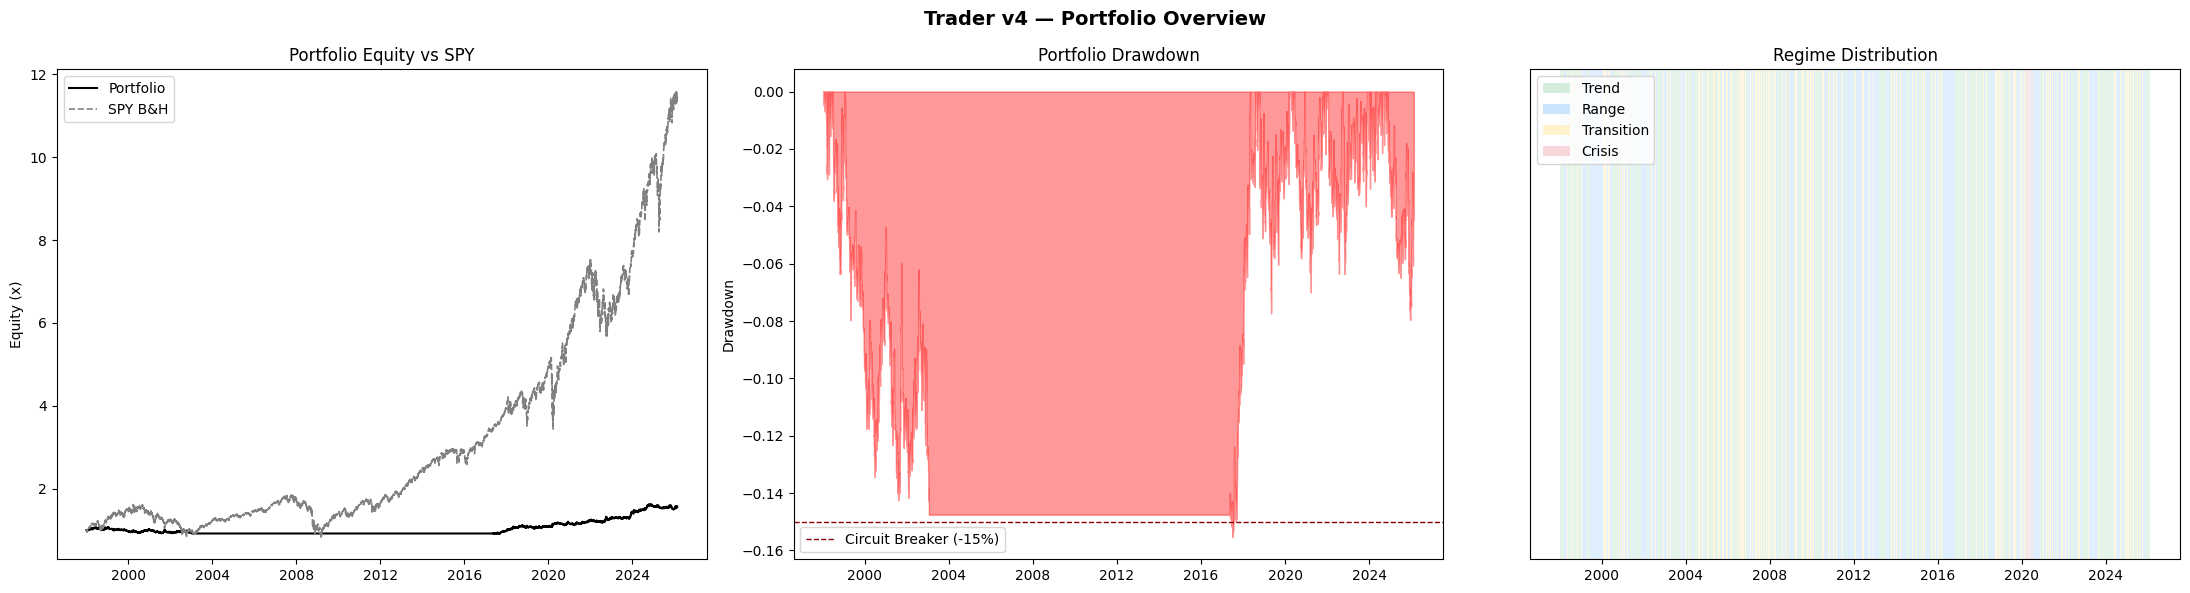

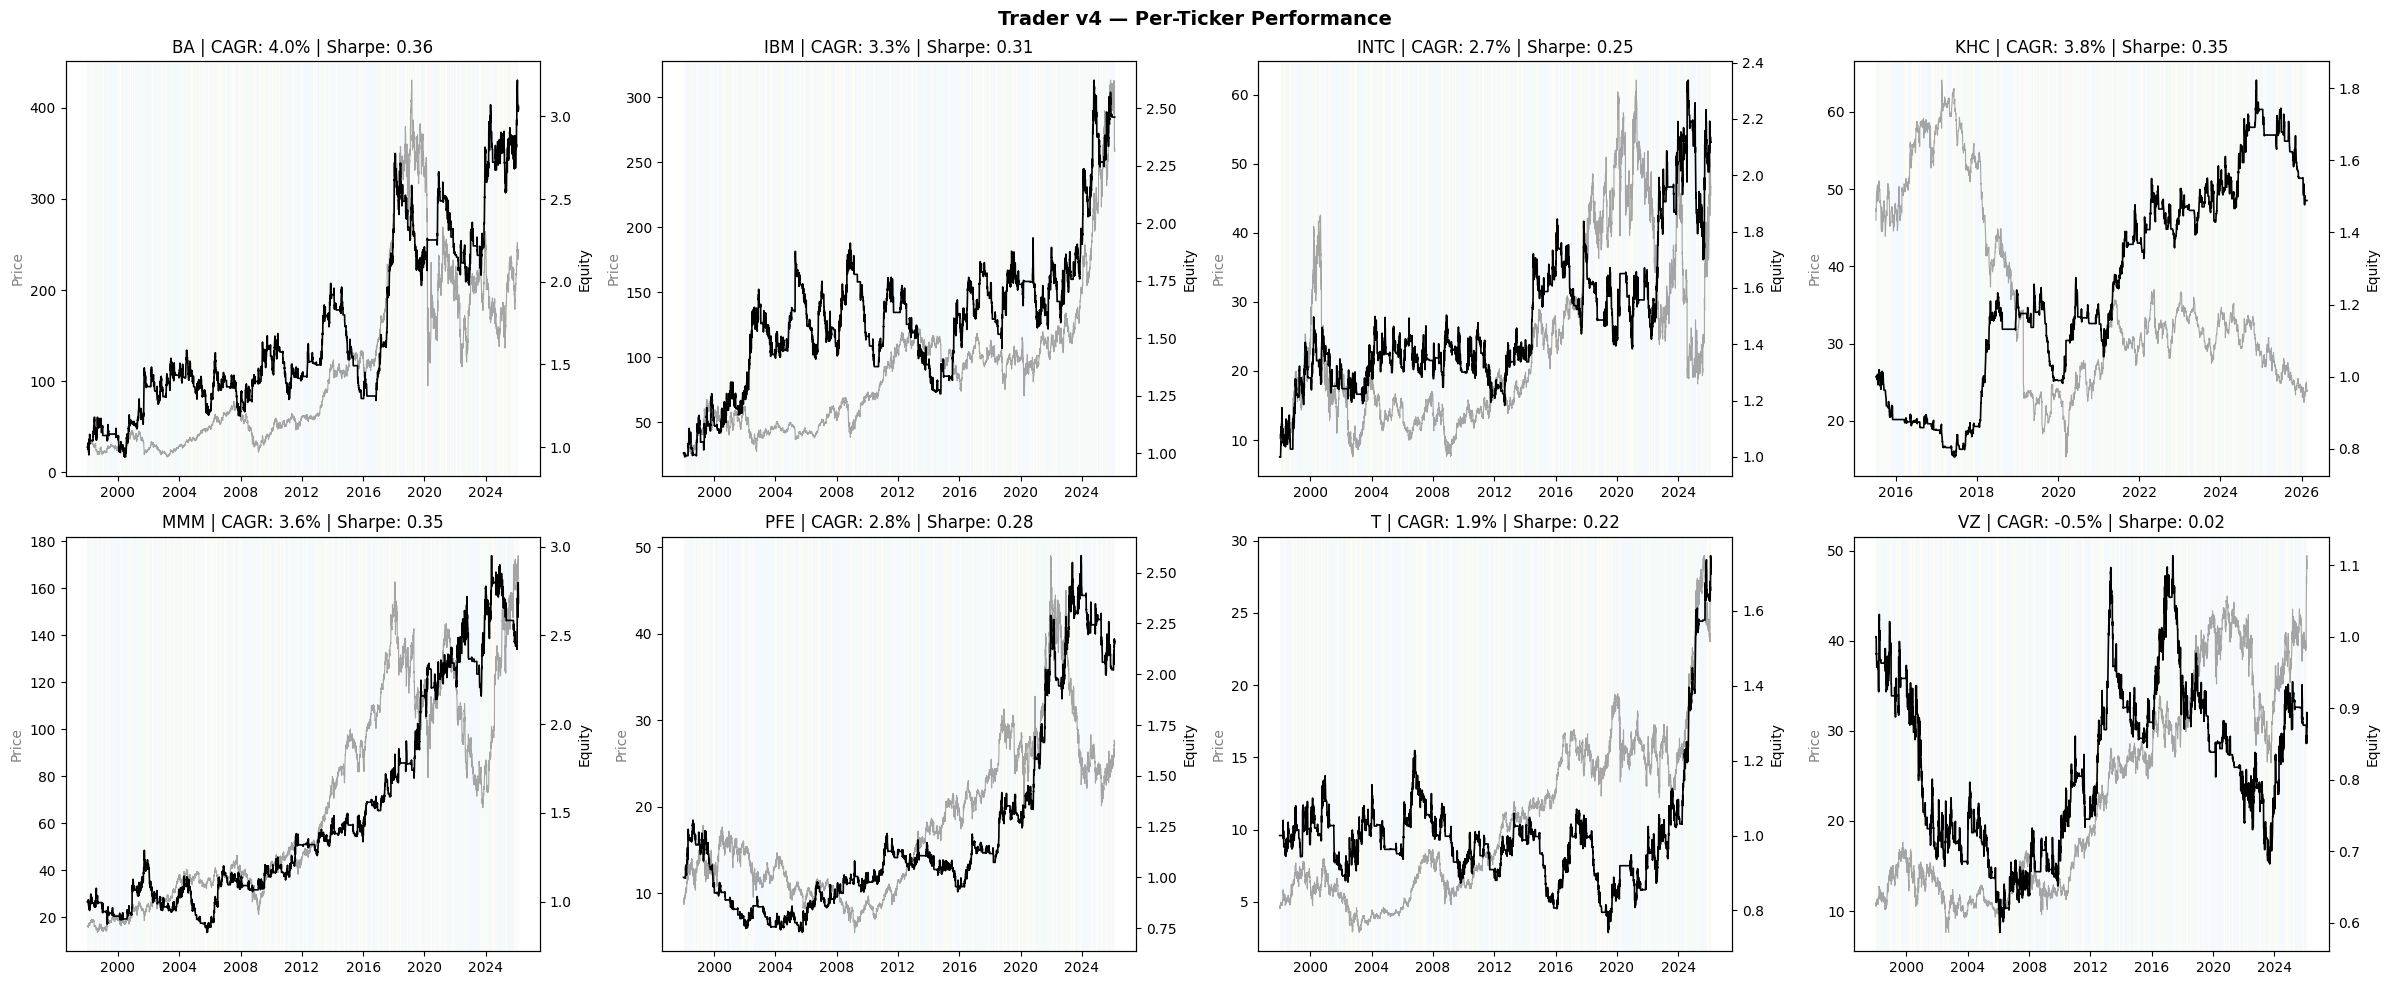

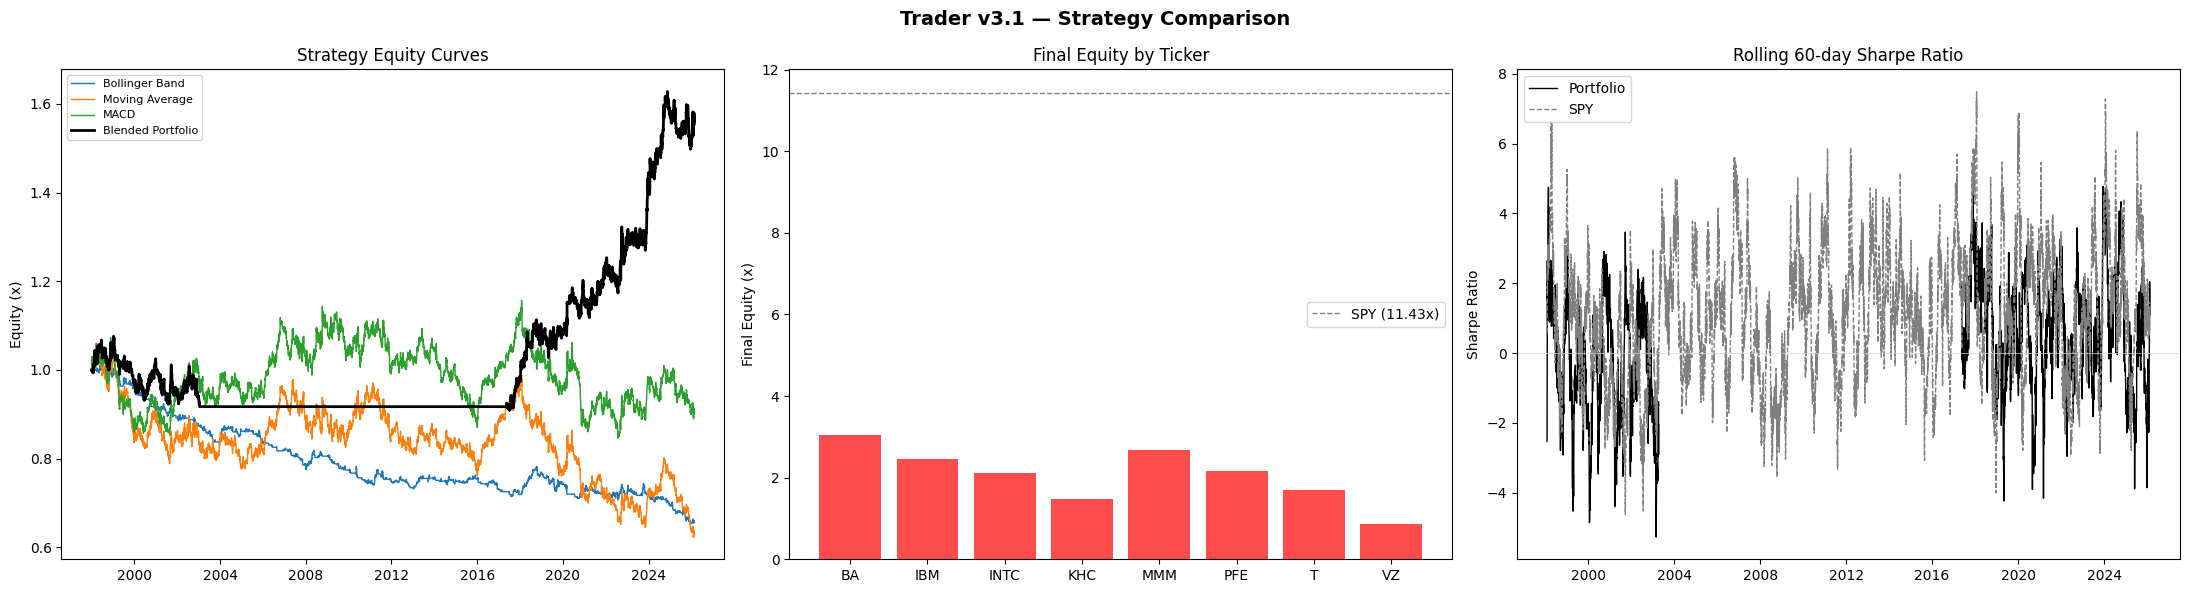

Done.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import yfinance as yf
from datetime import datetime
import warnings

warnings.filterwarnings("ignore")

# ========================== CONFIG ==========================
CONFIG = {
    "tickers": ["BA", "INTC", "IBM", "PFE", "T", "VZ", "MMM", "KHC"],
    "benchmark": "SPY",
    "start_date": "1998-01-01",
    "end_date": None,
    # RSI
    "rsi_len": 14,
    "rsi_long_thresh": 40,
    "rsi_trend_thresh": 50,
    # Bollinger Bands
    "bb_length": 16,
    "bb_mult": 2,
    # Moving Averages
    "ma_fast": 10,
    "ma_slow": 30,
    # MACD
    "macd_fast": 12,
    "macd_slow": 26,
    "macd_signal": 9,
    # ATR
    "atr_period": 14,
    # ADX
    "adx_period": 14,
    # Volume
    "vol_ma_period": 20,
    "vol_mult": 1.5,
    # Regime thresholds
    "adx_trend_thresh": 25,
    "adx_range_thresh": 20,
    "crisis_vol_mult": 3.0,
    "crisis_vol_window": 20,
    "crisis_vol_median_window": 252,
    "regime_hysteresis_days": 3,
    # Trailing stop
    "trailing_stop_atr_mult": 2.0,
    # Position sizing
    "target_risk": 0.02,
    # Risk management
    "daily_loss_limit": -0.03,
    "circuit_breaker_dd": -0.15,
    "circuit_breaker_reentry": -0.05,
    # Dynamic weighting
    "weight_lookback": 60,
    # Weekly MA for multi-timeframe
    "weekly_ma_period": 10,
}


# ========================== INDICATORS ==========================
def calc_rsi(price, period=14):
    """Wilder RSI."""
    delta = price.diff()
    gain = delta.clip(lower=0)
    loss = -delta.clip(upper=0)
    avg_gain = gain.ewm(alpha=1 / period, adjust=False).mean()
    avg_loss = loss.ewm(alpha=1 / period, adjust=False).mean()
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi


def calc_bollinger(price, length=16, mult=2):
    """Bollinger Bands: mid, upper, lower."""
    mid = price.rolling(length, min_periods=1).mean()
    std = price.rolling(length, min_periods=1).std()
    upper = mid + mult * std
    lower = mid - mult * std
    return mid, upper, lower


def calc_ma(price, fast=10, slow=30):
    """Fast and slow simple moving averages."""
    ma_fast = price.rolling(fast, min_periods=1).mean()
    ma_slow = price.rolling(slow, min_periods=1).mean()
    return ma_fast, ma_slow


def calc_macd(price, fast=12, slow=26, signal=9):
    """MACD line, signal line, histogram."""
    ema_fast = price.ewm(span=fast, adjust=False).mean()
    ema_slow = price.ewm(span=slow, adjust=False).mean()
    macd_line = ema_fast - ema_slow
    signal_line = macd_line.ewm(span=signal, adjust=False).mean()
    histogram = macd_line - signal_line
    return macd_line, signal_line, histogram


def calc_atr(high, low, close, period=14):
    """Average True Range using EWM."""
    prev_close = close.shift(1)
    tr1 = high - low
    tr2 = (high - prev_close).abs()
    tr3 = (low - prev_close).abs()
    tr = pd.concat([tr1, tr2, tr3], axis=1).max(axis=1)
    atr = tr.ewm(span=period, adjust=False).mean()
    return atr


def calc_adx(high, low, close, period=14):
    """ADX with Wilder smoothing."""
    alpha = 1 / period
    prev_high = high.shift(1)
    prev_low = low.shift(1)

    plus_dm = (high - prev_high).clip(lower=0)
    minus_dm = (prev_low - low).clip(lower=0)
    # Zero out the smaller DM
    plus_dm = np.where(plus_dm > minus_dm, plus_dm, 0.0)
    minus_dm_arr = np.where(minus_dm > pd.Series(plus_dm, index=high.index), minus_dm, 0.0)
    plus_dm = pd.Series(plus_dm, index=high.index)
    minus_dm = pd.Series(minus_dm_arr, index=high.index)

    atr = calc_atr(high, low, close, period)

    plus_di = 100 * plus_dm.ewm(alpha=alpha, adjust=False).mean() / atr
    minus_di = 100 * minus_dm.ewm(alpha=alpha, adjust=False).mean() / atr

    dx = 100 * (plus_di - minus_di).abs() / (plus_di + minus_di).replace(0, np.nan)
    dx = dx.fillna(0)
    adx = dx.ewm(alpha=alpha, adjust=False).mean()
    return adx, plus_di, minus_di


def calc_volume_confirm(volume, ma_period=20, mult=1.5):
    """Volume confirmation: True when volume exceeds mult * SMA(volume)."""
    vol_ma = volume.rolling(ma_period, min_periods=1).mean()
    return volume > mult * vol_ma


def compute_all_indicators(df, cfg):
    """Compute all indicators and add to dataframe."""
    price = df["Close"]
    df["RSI"] = calc_rsi(price, cfg["rsi_len"])

    df["BB_mid"], df["BB_upper"], df["BB_lower"] = calc_bollinger(
        price, cfg["bb_length"], cfg["bb_mult"]
    )

    df["MA_fast"], df["MA_slow"] = calc_ma(price, cfg["ma_fast"], cfg["ma_slow"])

    df["MACD_line"], df["MACD_signal"], df["MACD_hist"] = calc_macd(
        price, cfg["macd_fast"], cfg["macd_slow"], cfg["macd_signal"]
    )

    df["ATR"] = calc_atr(df["High"], df["Low"], price, cfg["atr_period"])

    df["ADX"], df["PLUS_DI"], df["MINUS_DI"] = calc_adx(
        df["High"], df["Low"], price, cfg["adx_period"]
    )

    df["VOL_CONFIRM"] = calc_volume_confirm(
        df["Volume"], cfg["vol_ma_period"], cfg["vol_mult"]
    )

    return df


# ========================== METRICS ==========================
def sharpe_ratio(returns, periods=252):
    """Annualized Sharpe ratio."""
    if returns.std() == 0:
        return 0.0
    return (returns.mean() * periods) / (returns.std() * np.sqrt(periods))


def sortino_ratio(returns, periods=252):
    """Annualized Sortino ratio."""
    downside = returns[returns < 0]
    if len(downside) == 0 or downside.std() == 0:
        return 0.0
    return (returns.mean() * periods) / (downside.std() * np.sqrt(periods))


def max_drawdown(equity):
    """Maximum drawdown from peak."""
    roll_max = equity.cummax()
    dd = (equity - roll_max) / roll_max
    return dd.min()


def drawdown_series(equity):
    """Full drawdown series."""
    roll_max = equity.cummax()
    return (equity - roll_max) / roll_max


def cagr(equity, periods_per_year=252):
    """Compound annual growth rate."""
    n_periods = len(equity)
    if n_periods < 2 or equity.iloc[0] == 0:
        return 0.0
    total_return = equity.iloc[-1] / equity.iloc[0]
    if total_return <= 0:
        return -1.0
    years = n_periods / periods_per_year
    return total_return ** (1 / years) - 1


def calmar_ratio(equity, periods_per_year=252):
    """Calmar ratio: CAGR / abs(MDD)."""
    c = cagr(equity, periods_per_year)
    mdd = abs(max_drawdown(equity))
    if mdd == 0:
        return 0.0
    return c / mdd


def profit_factor(returns):
    """Gross profit / gross loss."""
    gross_profit = returns[returns > 0].sum()
    gross_loss = abs(returns[returns < 0].sum())
    if gross_loss == 0:
        return np.inf if gross_profit > 0 else 0.0
    return gross_profit / gross_loss


def trade_stats(trade_log):
    """Compute trade statistics from a trade log DataFrame."""
    if trade_log is None or len(trade_log) == 0:
        return {
            "total_trades": 0, "win_rate": 0, "avg_win": 0, "avg_loss": 0,
            "avg_holding": 0, "max_consec_losses": 0, "best_trade": 0, "worst_trade": 0,
        }
    wins = trade_log[trade_log["pnl"] > 0]
    losses = trade_log[trade_log["pnl"] <= 0]

    # Max consecutive losses
    is_loss = (trade_log["pnl"] <= 0).astype(int)
    groups = is_loss.ne(is_loss.shift()).cumsum()
    consec = is_loss.groupby(groups).cumsum()
    max_consec = int(consec.max()) if len(consec) > 0 else 0

    return {
        "total_trades": len(trade_log),
        "win_rate": len(wins) / len(trade_log) if len(trade_log) > 0 else 0,
        "avg_win": wins["pnl"].mean() if len(wins) > 0 else 0,
        "avg_loss": losses["pnl"].mean() if len(losses) > 0 else 0,
        "avg_holding": trade_log["holding_days"].mean() if "holding_days" in trade_log.columns else 0,
        "max_consec_losses": max_consec,
        "best_trade": trade_log["pnl"].max(),
        "worst_trade": trade_log["pnl"].min(),
    }


# ========================== DATA LOADING ==========================
def load_data(cfg):
    """Download OHLCV data for all tickers + benchmark."""
    all_tickers = cfg["tickers"] + [cfg["benchmark"]]
    end = cfg["end_date"] or datetime.today().strftime("%Y-%m-%d")

    raw = yf.download(all_tickers, start=cfg["start_date"], end=end, progress=False)

    ticker_data = {}
    for t in all_tickers:
        try:
            tdf = pd.DataFrame()
            for col in ["Open", "High", "Low", "Close", "Volume"]:
                tdf[col] = raw[(col, t)]
            tdf.dropna(subset=["Close"], inplace=True)
            if len(tdf) > 100:
                ticker_data[t] = tdf
        except (KeyError, TypeError):
            print(f"  [WARN] Could not load data for {t}, skipping.")

    return ticker_data


# ========================== SIGNAL PIPELINE ==========================
def raw_signals_bb(df, cfg):
    """BB mean reversion: long below lower, short above upper, flat at mid."""
    price = df["Close"]
    signal = pd.Series(np.nan, index=df.index)
    signal[price < df["BB_lower"]] = 1
    signal[price > df["BB_upper"]] = -1
    signal[(price >= df["BB_lower"]) & (price <= df["BB_mid"])] = 0
    signal = signal.ffill().fillna(0)
    return signal


def raw_signals_ma(df, cfg):
    """MA crossover: long when fast > slow, short when fast < slow."""
    signal = np.where(df["MA_fast"] > df["MA_slow"], 1, -1)
    return pd.Series(signal, index=df.index, dtype=float)


def raw_signals_macd(df, cfg):
    """MACD: long when MACD line > signal, short when below."""
    signal = np.where(df["MACD_line"] > df["MACD_signal"], 1, -1)
    return pd.Series(signal, index=df.index, dtype=float)


def rsi_confirmation(signal, rsi, strategy, cfg):
    """RSI confirmation filter.
    BB longs: RSI < 40, BB shorts: RSI > 60
    MA/MACD longs: RSI > 50, MA/MACD shorts: RSI < 50
    """
    confirmed = signal.copy()
    if strategy == "bb":
        confirmed[(signal == 1) & (rsi >= cfg["rsi_long_thresh"])] = 0
        confirmed[(signal == -1) & (rsi <= 60)] = 0
    else:
        confirmed[(signal == 1) & (rsi <= cfg["rsi_trend_thresh"])] = 0
        confirmed[(signal == -1) & (rsi >= cfg["rsi_trend_thresh"])] = 0
    return confirmed


def volume_gate(signal, vol_confirm):
    """Only allow new entries on above-average volume; exits always pass."""
    prev_signal = signal.shift(1).fillna(0)
    is_new_entry = (signal != 0) & (signal != prev_signal)
    gated = signal.copy()
    gated[is_new_entry & ~vol_confirm] = prev_signal[is_new_entry & ~vol_confirm]
    return gated


def weekly_confirmation(signal, price, cfg):
    """Weekly MA trend filter: daily signal must agree with weekly trend."""
    weekly = price.resample("W").last().dropna()
    weekly_ma = weekly.rolling(cfg["weekly_ma_period"], min_periods=1).mean()
    weekly_trend = np.where(weekly > weekly_ma, 1, -1)
    weekly_trend = pd.Series(weekly_trend, index=weekly.index)
    # Forward-fill weekly trend to daily
    daily_trend = weekly_trend.reindex(price.index, method="ffill").fillna(0)

    filtered = signal.copy()
    # Block signals that disagree with weekly trend
    filtered[(signal == 1) & (daily_trend == -1)] = 0
    filtered[(signal == -1) & (daily_trend == 1)] = 0
    return filtered


def apply_trailing_stops(signal, price, atr, atr_mult=2.0):
    """Row-by-row trailing stop using ATR multiple. Returns adjusted positions."""
    pos = np.zeros(len(signal))
    trail_stop = np.zeros(len(signal))

    for i in range(1, len(signal)):
        sig = signal.iloc[i]
        p = price.iloc[i]
        a = atr.iloc[i]

        if pos[i - 1] == 0:
            # Enter new position
            if sig == 1:
                pos[i] = 1
                trail_stop[i] = p - atr_mult * a
            elif sig == -1:
                pos[i] = -1
                trail_stop[i] = p + atr_mult * a
            else:
                pos[i] = 0
                trail_stop[i] = 0
        elif pos[i - 1] == 1:
            # In long position
            new_stop = p - atr_mult * a
            trail_stop[i] = max(trail_stop[i - 1], new_stop)
            if p < trail_stop[i]:
                pos[i] = 0
                trail_stop[i] = 0
            elif sig == -1:
                pos[i] = -1
                trail_stop[i] = p + atr_mult * a
            else:
                pos[i] = 1
        elif pos[i - 1] == -1:
            # In short position
            new_stop = p + atr_mult * a
            trail_stop[i] = min(trail_stop[i - 1], new_stop) if trail_stop[i - 1] != 0 else new_stop
            if p > trail_stop[i]:
                pos[i] = 0
                trail_stop[i] = 0
            elif sig == 1:
                pos[i] = 1
                trail_stop[i] = p - atr_mult * a
            else:
                pos[i] = -1

    return pd.Series(pos, index=signal.index)


def position_sizing(position, atr, price, target_risk=0.02):
    """ATR-based inverse volatility position sizing. Returns size in [0, 1]."""
    atr_pct = atr / price
    atr_pct = atr_pct.replace(0, np.nan).ffill().fillna(0.01)
    raw_size = target_risk / atr_pct
    # Clip to [0, 1]
    size = raw_size.clip(0, 1)
    return size


def compute_strategy_returns(position, size, price):
    """Compute returns for a strategy given position, size, and price."""
    daily_ret = price.pct_change().fillna(0)
    # Shift position and size by 1 (trade on next day's open approx)
    pos = position.shift(1).fillna(0)
    sz = size.shift(1).fillna(0)
    strat_ret = pos * sz * daily_ret
    return strat_ret


def run_signal_pipeline(df, cfg, strategy_name):
    """Full signal pipeline for one strategy: raw -> RSI -> volume -> weekly -> trailing -> sizing -> returns."""
    # 1. Raw signal
    if strategy_name == "bb":
        raw = raw_signals_bb(df, cfg)
    elif strategy_name == "ma":
        raw = raw_signals_ma(df, cfg)
    elif strategy_name == "macd":
        raw = raw_signals_macd(df, cfg)
    else:
        raise ValueError(f"Unknown strategy: {strategy_name}")

    # 2. RSI confirmation
    confirmed = rsi_confirmation(raw, df["RSI"], strategy_name, cfg)

    # 3. Volume gate
    gated = volume_gate(confirmed, df["VOL_CONFIRM"])

    # 4. Weekly confirmation
    weekly_filtered = weekly_confirmation(gated, df["Close"], cfg)

    # 5. Trailing stops
    stopped = apply_trailing_stops(weekly_filtered, df["Close"], df["ATR"], cfg["trailing_stop_atr_mult"])

    # 6. Position sizing
    size = position_sizing(stopped, df["ATR"], df["Close"], cfg["target_risk"])

    # 7. Returns
    strat_ret = compute_strategy_returns(stopped, size, df["Close"])

    return stopped, size, strat_ret


# ========================== REGIME DETECTION ==========================
def detect_regimes(df, cfg):
    """3-regime detection with hysteresis and transition blending.

    Regimes: trend, range, transition, crisis
    """
    adx = df["ADX"]
    daily_ret = df["Close"].pct_change().fillna(0)

    # Crisis detection: rolling vol > 3x rolling median of vol
    rolling_vol = daily_ret.rolling(cfg["crisis_vol_window"], min_periods=1).std()
    rolling_vol_median = rolling_vol.rolling(cfg["crisis_vol_median_window"], min_periods=1).median()
    is_crisis = rolling_vol > cfg["crisis_vol_mult"] * rolling_vol_median

    # Raw regime assignment
    raw_regime = pd.Series("transition", index=df.index)
    raw_regime[adx > cfg["adx_trend_thresh"]] = "trend"
    raw_regime[adx < cfg["adx_range_thresh"]] = "range"
    raw_regime[is_crisis] = "crisis"

    # Hysteresis: regime must persist for N consecutive days to switch (crisis = immediate)
    regime = pd.Series("range", index=df.index)
    current = "range"
    count = 0
    hysteresis_days = cfg["regime_hysteresis_days"]

    for i in range(len(raw_regime)):
        r = raw_regime.iloc[i]
        if r == "crisis":
            current = "crisis"
            count = 0
        elif r == current:
            count = 0
        else:
            count += 1
            if count >= hysteresis_days:
                current = r
                count = 0
        regime.iloc[i] = current

    # Transition blending weights
    adx_trend_th = cfg["adx_trend_thresh"]
    adx_range_th = cfg["adx_range_thresh"]
    trend_weight = ((adx - adx_range_th) / (adx_trend_th - adx_range_th)).clip(0, 1)

    return regime, trend_weight, rolling_vol


def blend_strategy_returns(ret_bb, ret_ma, ret_macd, regime, trend_weight):
    """Blend strategy returns based on regime.

    Trend:      50% MA + 50% MACD
    Range:      100% BB
    Transition: Linear blend between trend and range
    Crisis:     100% cash (0)
    """
    blended = pd.Series(0.0, index=regime.index)

    trend_ret = 0.5 * ret_ma + 0.5 * ret_macd
    range_ret = ret_bb

    for i in range(len(regime)):
        r = regime.iloc[i]
        if r == "crisis":
            blended.iloc[i] = 0.0
        elif r == "trend":
            blended.iloc[i] = trend_ret.iloc[i]
        elif r == "range":
            blended.iloc[i] = range_ret.iloc[i]
        else:  # transition
            tw = trend_weight.iloc[i]
            blended.iloc[i] = tw * trend_ret.iloc[i] + (1 - tw) * range_ret.iloc[i]

    return blended


# ========================== RISK MANAGEMENT ==========================
def apply_daily_loss_limit(returns, limit=-0.03):
    """Clip daily returns at the loss limit."""
    return returns.clip(lower=limit)


def apply_circuit_breaker(equity, dd_threshold=-0.15, reentry_threshold=-0.05):
    """Circuit breaker: go cash if drawdown exceeds threshold, re-enter when recovered."""
    dd = drawdown_series(equity)
    active = pd.Series(True, index=equity.index)
    in_cash = False

    for i in range(len(dd)):
        if in_cash:
            if dd.iloc[i] > reentry_threshold:
                in_cash = False
                active.iloc[i] = True
            else:
                active.iloc[i] = False
        else:
            if dd.iloc[i] < dd_threshold:
                in_cash = True
                active.iloc[i] = False
            else:
                active.iloc[i] = True

    return active


# ========================== TRADE LOG ==========================
def build_trade_log(position, price, strategy_name, ticker):
    """Build trade log from position changes."""
    trades = []
    in_trade = False
    entry_date = None
    entry_price = None
    direction = 0

    for i in range(len(position)):
        pos = position.iloc[i]
        dt = position.index[i]
        p = price.iloc[i]

        if not in_trade and pos != 0:
            # Entry
            in_trade = True
            entry_date = dt
            entry_price = p
            direction = pos
        elif in_trade and (pos != direction):
            # Exit
            if direction == 1:
                pnl = (p - entry_price) / entry_price
            else:
                pnl = (entry_price - p) / entry_price
            holding = (dt - entry_date).days
            trades.append({
                "ticker": ticker,
                "strategy": strategy_name,
                "direction": "long" if direction == 1 else "short",
                "entry_date": entry_date,
                "exit_date": dt,
                "entry_price": entry_price,
                "exit_price": p,
                "holding_days": holding,
                "pnl": pnl,
            })
            in_trade = False
            # If new position opened immediately
            if pos != 0:
                in_trade = True
                entry_date = dt
                entry_price = p
                direction = pos

    # Close any open trade at end
    if in_trade and len(position) > 0:
        p = price.iloc[-1]
        dt = position.index[-1]
        if direction == 1:
            pnl = (p - entry_price) / entry_price
        else:
            pnl = (entry_price - p) / entry_price
        holding = (dt - entry_date).days
        trades.append({
            "ticker": ticker,
            "strategy": strategy_name,
            "direction": "long" if direction == 1 else "short",
            "entry_date": entry_date,
            "exit_date": dt,
            "entry_price": entry_price,
            "exit_price": p,
            "holding_days": holding,
            "pnl": pnl,
        })

    if len(trades) == 0:
        return pd.DataFrame()
    return pd.DataFrame(trades)


# ========================== PER-TICKER PIPELINE ==========================
def run_strategy_pipeline(df, cfg, ticker):
    """Run full strategy pipeline for one ticker.

    Returns dict with per-strategy returns, blended returns, regime info, equity, trade logs.
    """
    # Compute indicators
    df = compute_all_indicators(df, cfg)

    # Run each strategy pipeline
    pos_bb, size_bb, ret_bb = run_signal_pipeline(df, cfg, "bb")
    pos_ma, size_ma, ret_ma = run_signal_pipeline(df, cfg, "ma")
    pos_macd, size_macd, ret_macd = run_signal_pipeline(df, cfg, "macd")

    # Regime detection
    regime, trend_weight, rolling_vol = detect_regimes(df, cfg)

    # Blend returns based on regime
    blended_ret = blend_strategy_returns(ret_bb, ret_ma, ret_macd, regime, trend_weight)

    # Daily loss limit
    blended_ret = apply_daily_loss_limit(blended_ret, cfg["daily_loss_limit"])

    # Equity curve
    equity = (1 + blended_ret).cumprod()

    # Trade logs
    log_bb = build_trade_log(pos_bb, df["Close"], "bb", ticker)
    log_ma = build_trade_log(pos_ma, df["Close"], "ma", ticker)
    log_macd = build_trade_log(pos_macd, df["Close"], "macd", ticker)
    all_logs = pd.concat([log_bb, log_ma, log_macd], ignore_index=True)

    return {
        "df": df,
        "ret_bb": ret_bb,
        "ret_ma": ret_ma,
        "ret_macd": ret_macd,
        "blended_ret": blended_ret,
        "equity": equity,
        "regime": regime,
        "trend_weight": trend_weight,
        "rolling_vol": rolling_vol,
        "trade_log": all_logs,
        "ticker": ticker,
    }


# ========================== DYNAMIC WEIGHTING ==========================
def compute_dynamic_weights(ticker_results, lookback=60):
    """Dynamic weighting based on rolling Sharpe per ticker."""
    tickers = list(ticker_results.keys())
    if len(tickers) == 0:
        return {}

    # Align all return series to common index
    ret_dict = {t: ticker_results[t]["blended_ret"] for t in tickers}
    ret_df = pd.DataFrame(ret_dict)

    # Rolling Sharpe (annualized)
    rolling_mean = ret_df.rolling(lookback, min_periods=20).mean() * 252
    rolling_std = ret_df.rolling(lookback, min_periods=20).std() * np.sqrt(252)
    rolling_sharpe = rolling_mean / rolling_std.replace(0, np.nan)
    rolling_sharpe = rolling_sharpe.fillna(0)

    # Shift to non-negative, then normalize to weights summing to 1
    min_sharpe = rolling_sharpe.min(axis=1)
    shifted = rolling_sharpe.sub(min_sharpe, axis=0)
    row_sum = shifted.sum(axis=1)
    weights = shifted.div(row_sum.replace(0, np.nan), axis=0).fillna(1.0 / len(tickers))

    return weights


def aggregate_portfolio(ticker_results, weights):
    """Aggregate per-ticker returns into portfolio using dynamic weights."""
    tickers = list(ticker_results.keys())
    ret_df = pd.DataFrame({t: ticker_results[t]["blended_ret"] for t in tickers})

    # Shift weights by 1 day to avoid look-ahead bias:
    # weight decisions are based on data up to yesterday, applied to today's return
    portfolio_ret = (ret_df * weights.shift(1)).sum(axis=1)
    return portfolio_ret


# ========================== CONSOLE REPORT ==========================
def print_report(ticker_results, portfolio_equity, portfolio_ret, spy_equity, spy_ret):
    """Print comprehensive console report."""
    print("\n" + "=" * 70)
    print("  TRADER v4 — PORTFOLIO REPORT")
    print("=" * 70)

    # Portfolio metrics
    p_sharpe = sharpe_ratio(portfolio_ret)
    p_sortino = sortino_ratio(portfolio_ret)
    p_mdd = max_drawdown(portfolio_equity)
    p_cagr = cagr(portfolio_equity)
    p_calmar = calmar_ratio(portfolio_equity)
    p_pf = profit_factor(portfolio_ret)

    spy_sharpe = sharpe_ratio(spy_ret)
    spy_mdd = max_drawdown(spy_equity)
    spy_cagr = cagr(spy_equity)

    print(f"\n{'PORTFOLIO':>20} {'SPY B&H':>15}")
    print(f"  {'Sharpe':.<20} {p_sharpe:>8.3f} {spy_sharpe:>15.3f}")
    print(f"  {'Sortino':.<20} {p_sortino:>8.3f}")
    print(f"  {'Calmar':.<20} {p_calmar:>8.3f}")
    print(f"  {'CAGR':.<20} {p_cagr:>8.2%} {spy_cagr:>14.2%}")
    print(f"  {'Max Drawdown':.<20} {p_mdd:>8.2%} {spy_mdd:>14.2%}")
    print(f"  {'Profit Factor':.<20} {p_pf:>8.2f}")
    print(f"  {'Final Equity':.<20} {portfolio_equity.iloc[-1]:>8.2f}x {spy_equity.iloc[-1]:>14.2f}x")

    # Per-ticker summary
    print("\n" + "-" * 70)
    print("  PER-TICKER SUMMARY")
    print("-" * 70)
    print(f"  {'Ticker':<8} {'CAGR':>8} {'Sharpe':>8} {'MDD':>9} {'Final':>8} {'Trades':>8}")

    all_logs = []
    for t in sorted(ticker_results.keys()):
        res = ticker_results[t]
        eq = res["equity"]
        ret = res["blended_ret"]
        t_cagr = cagr(eq)
        t_sharpe = sharpe_ratio(ret)
        t_mdd = max_drawdown(eq)
        t_final = eq.iloc[-1]
        n_trades = len(res["trade_log"])
        print(f"  {t:<8} {t_cagr:>7.2%} {t_sharpe:>8.3f} {t_mdd:>8.2%} {t_final:>7.2f}x {n_trades:>8}")
        if len(res["trade_log"]) > 0:
            all_logs.append(res["trade_log"])

    # Trade stats
    if len(all_logs) > 0:
        master_log = pd.concat(all_logs, ignore_index=True)
        stats = trade_stats(master_log)
        print("\n" + "-" * 70)
        print("  TRADE STATISTICS")
        print("-" * 70)
        print(f"  Total Trades:           {stats['total_trades']}")
        print(f"  Win Rate:               {stats['win_rate']:.2%}")
        print(f"  Avg Win:                {stats['avg_win']:.4f}")
        print(f"  Avg Loss:               {stats['avg_loss']:.4f}")
        print(f"  Avg Holding (days):     {stats['avg_holding']:.1f}")
        print(f"  Max Consec Losses:      {stats['max_consec_losses']}")
        print(f"  Best Trade:             {stats['best_trade']:.4f}")
        print(f"  Worst Trade:            {stats['worst_trade']:.4f}")

    # Regime distribution
    print("\n" + "-" * 70)
    print("  REGIME DISTRIBUTION (avg across tickers)")
    print("-" * 70)
    regime_stats = {"trend": [], "range": [], "transition": [], "crisis": []}
    for t in ticker_results:
        regime = ticker_results[t]["regime"]
        total = len(regime)
        for r in regime_stats:
            regime_stats[r].append((regime == r).sum() / total)

    for r in ["trend", "range", "transition", "crisis"]:
        avg_pct = np.mean(regime_stats[r])
        print(f"  {r.capitalize():<15} {avg_pct:>7.2%}")

    print("=" * 70)


# ========================== PLOTTING ==========================
REGIME_COLORS = {"trend": "#d4edda", "range": "#cce5ff", "transition": "#fff3cd", "crisis": "#f8d7da"}


def add_regime_shading(ax, regime, alpha=0.3):
    """Add colored background bands for regimes."""
    dates = regime.index
    current = regime.iloc[0]
    start = dates[0]
    for i in range(1, len(regime)):
        if regime.iloc[i] != current or i == len(regime) - 1:
            end = dates[i]
            ax.axvspan(start, end, alpha=alpha, color=REGIME_COLORS.get(current, "white"), linewidth=0)
            current = regime.iloc[i]
            start = end


def plot_portfolio_overview(portfolio_equity, spy_equity, portfolio_ret, regime_agg):
    """Figure 1: Portfolio Overview (1x3)."""
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    fig.suptitle("Trader v4 — Portfolio Overview", fontsize=14, fontweight="bold")

    # 1. Portfolio equity vs SPY
    ax = axes[0]
    ax.plot(portfolio_equity.index, portfolio_equity.values, color="black", linewidth=1.5, label="Portfolio")
    ax.plot(spy_equity.index, spy_equity.values, color="gray", linestyle="--", linewidth=1.2, label="SPY B&H")
    ax.set_title("Portfolio Equity vs SPY")
    ax.legend(loc="upper left")
    ax.set_ylabel("Equity (x)")

    # 2. Drawdown
    ax = axes[1]
    dd = drawdown_series(portfolio_equity)
    ax.fill_between(dd.index, dd.values, 0, color="red", alpha=0.4)
    ax.axhline(y=-0.15, color="darkred", linestyle="--", linewidth=1, label="Circuit Breaker (-15%)")
    ax.set_title("Portfolio Drawdown")
    ax.set_ylabel("Drawdown")
    ax.legend(loc="lower left")

    # 3. Regime distribution
    ax = axes[2]
    if regime_agg is not None:
        add_regime_shading(ax, regime_agg, alpha=0.6)
    ax.set_title("Regime Distribution")
    ax.set_yticks([])
    # Add legend for regimes
    from matplotlib.patches import Patch
    legend_elements = [Patch(facecolor=REGIME_COLORS[r], label=r.capitalize()) for r in REGIME_COLORS]
    ax.legend(handles=legend_elements, loc="upper left")

    plt.tight_layout()
    return fig


def plot_per_ticker_grid(ticker_results, spy_equity):
    """Figure 2: Per-Ticker Grid (2x4)."""
    tickers = sorted(ticker_results.keys())
    n = len(tickers)
    rows = 2
    cols = 4
    fig, axes = plt.subplots(rows, cols, figsize=(24, 10))
    fig.suptitle("Trader v4 — Per-Ticker Performance", fontsize=14, fontweight="bold")

    for idx, t in enumerate(tickers):
        r = idx // cols
        c = idx % cols
        ax = axes[r, c] if rows > 1 else axes[c]

        res = ticker_results[t]
        price = res["df"]["Close"]
        eq = res["equity"]
        regime = res["regime"]

        # Regime shading
        add_regime_shading(ax, regime, alpha=0.2)

        # Price on primary axis
        ax.plot(price.index, price.values, color="gray", alpha=0.7, linewidth=0.8)
        ax.set_ylabel("Price", color="gray")

        # Equity on secondary axis
        ax2 = ax.twinx()
        ax2.plot(eq.index, eq.values, color="black", linewidth=1.2)
        ax2.set_ylabel("Equity", color="black")

        t_cagr = cagr(eq)
        t_sharpe = sharpe_ratio(res["blended_ret"])
        ax.set_title(f"{t} | CAGR: {t_cagr:.1%} | Sharpe: {t_sharpe:.2f}")

    # Hide unused subplots
    for idx in range(n, rows * cols):
        r = idx // cols
        c = idx % cols
        ax = axes[r, c] if rows > 1 else axes[c]
        ax.set_visible(False)

    plt.tight_layout()
    return fig


def plot_strategy_comparison(ticker_results, portfolio_equity, spy_equity, portfolio_ret, spy_ret):
    """Figure 3: Strategy Comparison (1x3)."""
    fig, axes = plt.subplots(1, 3, figsize=(22, 6))
    fig.suptitle("Trader v3.1 — Strategy Comparison", fontsize=14, fontweight="bold")

    tickers = sorted(ticker_results.keys())

    # 1. Aggregate equity curves per strategy + blended
    ax = axes[0]
    strat_equity = {}
    for strat in ["bb", "ma", "macd"]:
        strat_ret_all = pd.DataFrame({t: ticker_results[t][f"ret_{strat}"] for t in tickers})
        avg_ret = strat_ret_all.mean(axis=1)
        strat_eq = (1 + avg_ret).cumprod()
        strat_equity[strat] = strat_eq
        label = {"bb": "Bollinger Band", "ma": "Moving Average", "macd": "MACD"}[strat]
        ax.plot(strat_eq.index, strat_eq.values, linewidth=1, label=label)

    ax.plot(portfolio_equity.index, portfolio_equity.values, color="black", linewidth=2, label="Blended Portfolio")
    ax.set_title("Strategy Equity Curves")
    ax.legend(loc="upper left", fontsize=8)
    ax.set_ylabel("Equity (x)")

    # 2. Per-ticker final equity bar chart
    ax = axes[1]
    spy_final = spy_equity.iloc[-1]
    finals = {t: ticker_results[t]["equity"].iloc[-1] for t in tickers}
    colors = ["green" if v >= spy_final else "red" for v in finals.values()]
    bars = ax.bar(list(finals.keys()), list(finals.values()), color=colors, alpha=0.7)
    ax.axhline(y=spy_final, color="gray", linestyle="--", linewidth=1, label=f"SPY ({spy_final:.2f}x)")
    ax.set_title("Final Equity by Ticker")
    ax.legend()
    ax.set_ylabel("Final Equity (x)")

    # 3. Rolling 60-day Sharpe: portfolio vs SPY
    ax = axes[2]
    lookback = 60
    port_rolling_sharpe = (
        portfolio_ret.rolling(lookback, min_periods=20).mean()
        / portfolio_ret.rolling(lookback, min_periods=20).std()
    ) * np.sqrt(252)
    spy_rolling_sharpe = (
        spy_ret.rolling(lookback, min_periods=20).mean()
        / spy_ret.rolling(lookback, min_periods=20).std()
    ) * np.sqrt(252)
    ax.plot(port_rolling_sharpe.index, port_rolling_sharpe.values, color="black", linewidth=1, label="Portfolio")
    ax.plot(spy_rolling_sharpe.index, spy_rolling_sharpe.values, color="gray", linestyle="--", linewidth=1, label="SPY")
    ax.axhline(y=0, color="lightgray", linewidth=0.5)
    ax.set_title("Rolling 60-day Sharpe Ratio")
    ax.legend(loc="upper left")
    ax.set_ylabel("Sharpe Ratio")

    plt.tight_layout()
    return fig


# ========================== MAIN ==========================
def main():
    cfg = CONFIG.copy()

    print("Trader v4 — Loading data...")
    ticker_data = load_data(cfg)

    available_tickers = [t for t in cfg["tickers"] if t in ticker_data]
    if len(available_tickers) == 0:
        print("ERROR: No ticker data loaded. Exiting.")
        return

    benchmark = cfg["benchmark"]
    if benchmark not in ticker_data:
        print(f"ERROR: Benchmark {benchmark} not loaded. Exiting.")
        return

    # SPY benchmark
    spy_df = ticker_data[benchmark]
    spy_ret = spy_df["Close"].pct_change().fillna(0)
    spy_equity = (1 + spy_ret).cumprod()

    # Run pipeline per ticker
    print(f"Running strategy pipeline for {len(available_tickers)} tickers...")
    ticker_results = {}
    for t in available_tickers:
        print(f"  Processing {t}...")
        df = ticker_data[t].copy()
        result = run_strategy_pipeline(df, cfg, t)
        ticker_results[t] = result

    # Dynamic weighting
    print("Computing dynamic weights...")
    weights = compute_dynamic_weights(ticker_results, cfg["weight_lookback"])

    # Aggregate portfolio
    portfolio_ret = aggregate_portfolio(ticker_results, weights)

    # Daily loss limit on portfolio level
    portfolio_ret = apply_daily_loss_limit(portfolio_ret, cfg["daily_loss_limit"])

    # Build equity for circuit breaker
    portfolio_equity = (1 + portfolio_ret).cumprod()

    # Circuit breaker
    active = apply_circuit_breaker(portfolio_equity, cfg["circuit_breaker_dd"], cfg["circuit_breaker_reentry"])
    portfolio_ret = portfolio_ret * active.astype(float)
    portfolio_equity = (1 + portfolio_ret).cumprod()

    # Align SPY to portfolio dates
    common_idx = portfolio_equity.index.intersection(spy_equity.index)
    spy_equity = spy_equity.reindex(common_idx)
    spy_ret = spy_ret.reindex(common_idx).fillna(0)
    portfolio_equity = portfolio_equity.reindex(common_idx)
    portfolio_ret = portfolio_ret.reindex(common_idx).fillna(0)

    # Use first ticker's regime as representative for portfolio plot
    first_ticker = available_tickers[0]
    regime_agg = ticker_results[first_ticker]["regime"].reindex(common_idx, method="ffill")

    # Console report
    print_report(ticker_results, portfolio_equity, portfolio_ret, spy_equity, spy_ret)

    # Plots
    print("\nGenerating plots...")
    fig1 = plot_portfolio_overview(portfolio_equity, spy_equity, portfolio_ret, regime_agg)
    fig2 = plot_per_ticker_grid(ticker_results, spy_equity)
    fig3 = plot_strategy_comparison(ticker_results, portfolio_equity, spy_equity, portfolio_ret, spy_ret)

    plt.show()
    print("Done.")


if __name__ == "__main__":
    main()
